# Lab 3 — Visualization notebook

**This notebook is a working tool, not a deliverable — you do NOT submit it.**

It contains no logic of its own: it imports your finished functions from `../src/lab03.py`
and plots their output. If a cell below fails, the bug is in your `.py`, not in the plot.

Your job: complete the three plot cells, then **export each figure and paste it into
`report.pdf`** (right-click → Save image as…, or `plt.savefig('fig1.png', dpi=150)`).
Figures 1–3 are required by the report template.

In [1]:
import sys
sys.path.insert(0, '../src')
import numpy as np
import matplotlib.pyplot as plt
import lab03

data = lab03.load_data('../data/lab03_scene.npz')
X, labels_true = data['X'], data['labels']

rng = np.random.default_rng(lab03.SEED)
centers, km_labels, inertia = lab03.kmeans(X, lab03.K_OBJECTS, rng)      # Task 1
means, covs, weights, resp, lls = lab03.gmm_em(X, lab03.K_OBJECTS, rng)  # Task 2
gmm_labels = resp.argmax(axis=1)
print(f'{len(X)} pts, k-means inertia {inertia:.2f}, '
      f'ARI k-means {lab03.adjusted_rand_index(labels_true, km_labels):.4f}, '
      f'ARI GMM {lab03.adjusted_rand_index(labels_true, gmm_labels):.4f}')

1614 pts, k-means inertia 281.81, ARI k-means 0.6082, ARI GMM 0.9104


## Plot 1 — Report Figure 1: the scene, K-means vs GMM labels

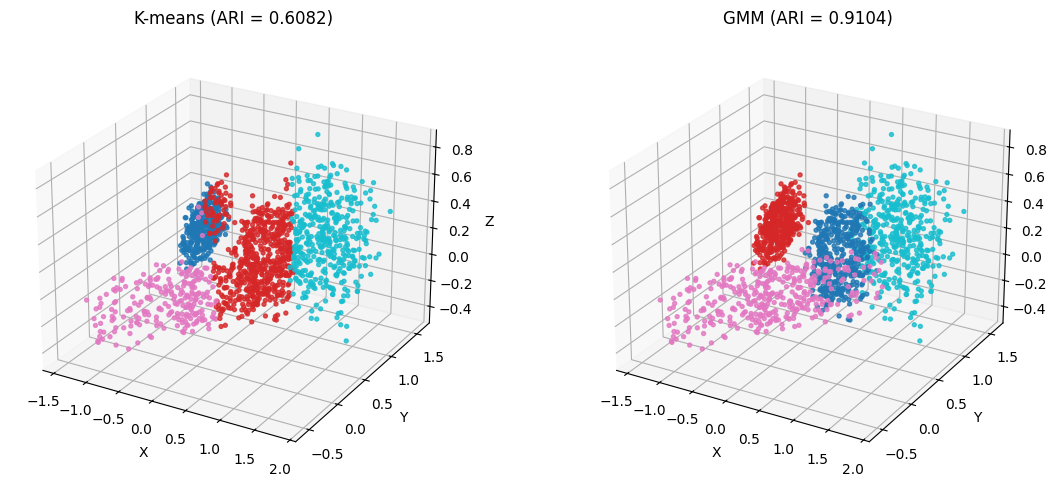

In [2]:
# ============ TODO (Plot 1) ============
# Two 3D scatter panels side by side (projection='3d'):
#   left  = X colored by km_labels, right = X colored by gmm_labels.
# Same viewing angle on both (e.g., ax.view_init(elev=25, azim=-60)).
# Put the ARI of each method in the panel title so the figure carries its
# own evidence. Look for where k-means cuts the long box / merges objects.
# =======================================

# ============ TODO (Plot 1) ============

ari_kmeans = lab03.adjusted_rand_index(labels_true, km_labels)
ari_gmm = lab03.adjusted_rand_index(labels_true, gmm_labels)

fig = plt.figure(figsize=(12, 5))

# -------------------------
# Left: K-means
# -------------------------
ax1 = fig.add_subplot(1, 2, 1, projection='3d')

ax1.scatter(
    X[:, 0],
    X[:, 1],
    X[:, 2],
    c=km_labels,
    cmap='tab10',
    s=8,
    alpha=0.8
)

ax1.set_title(f'K-means (ARI = {ari_kmeans:.4f})')
ax1.set_xlabel('X')
ax1.set_ylabel('Y')
ax1.set_zlabel('Z')

ax1.view_init(elev=25, azim=-60)


# -------------------------
# Right: GMM
# -------------------------
ax2 = fig.add_subplot(1, 2, 2, projection='3d')

ax2.scatter(
    X[:, 0],
    X[:, 1],
    X[:, 2],
    c=gmm_labels,
    cmap='tab10',
    s=8,
    alpha=0.8
)

ax2.set_title(f'GMM (ARI = {ari_gmm:.4f})')
ax2.set_xlabel('X')
ax2.set_ylabel('Y')
ax2.set_zlabel('Z')

# 같은 viewing angle
ax2.view_init(elev=25, azim=-60)

plt.tight_layout()

# notebook 폴더의 상위 폴더에 저장
plt.savefig('../fig1.png', dpi=200, bbox_inches='tight')

plt.show()

## Plot 2 — Report Figure 2: the EM log-likelihood trace

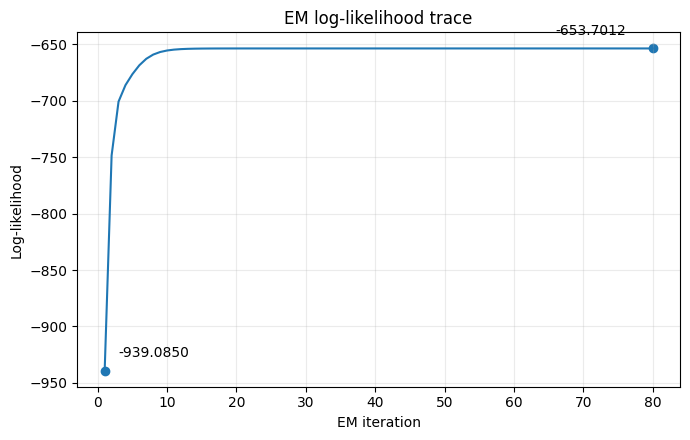

In [3]:
# ============ TODO (Plot 2) ============
# Line plot of lls (the trace returned by gmm_em above) vs iteration.
# The trace must never decrease — that is EM's guarantee. Annotate the
# first and final values (they go into your report's Table 1).
# =======================================
# ============ TODO (Plot 2) ============

iterations = np.arange(1, len(lls) + 1)

plt.figure(figsize=(7, 4.5))

plt.plot(
    iterations,
    lls
)

# first / final point 표시
plt.scatter(
    [iterations[0], iterations[-1]],
    [lls[0], lls[-1]]
)

# 첫 값 annotation
plt.annotate(
    f'{lls[0]:.4f}',
    (iterations[0], lls[0]),
    xytext=(10, 10),
    textcoords='offset points'
)

# 마지막 값 annotation
plt.annotate(
    f'{lls[-1]:.4f}',
    (iterations[-1], lls[-1]),
    xytext=(-70, 10),
    textcoords='offset points'
)

plt.xlabel('EM iteration')
plt.ylabel('Log-likelihood')
plt.title('EM log-likelihood trace')

plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig('../fig2.png', dpi=200, bbox_inches='tight')

plt.show()


## Plot 3 — Report Figure 3: the BIC curve

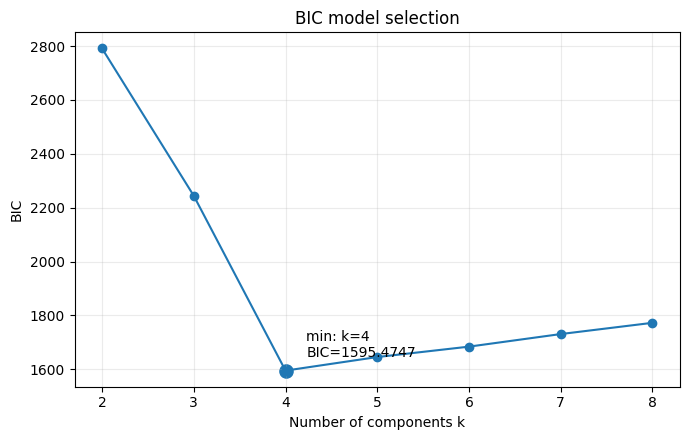

BIC values:
k=2: 2791.0291
k=3: 2244.1721
k=4: 1595.4747
k=5: 1645.8338
k=6: 1684.4573
k=7: 1731.1309
k=8: 1772.8624
best_k: 4


In [5]:
# ============ TODO (Plot 3) ============
# Line plot of BIC vs k over lab03.K_RANGE, minimum marked.
# To reproduce the exact bic_k* values of results.json, call
#     bics, best_k = lab03.select_k(X, lab03.K_RANGE, rng)
# with the SAME rng object the setup cell created (run_experiment uses one
# generator for all three steps, so its state at this point matters).
# A fresh generator gives slightly different BIC values (same minimum).
# =======================================
# ============ TODO (Plot 3) ============

# 중요:
# setup cell에서 만든 SAME rng를 그대로 사용
bics, best_k = lab03.select_k(
    X,
    lab03.K_RANGE,
    rng
)

ks = np.array(lab03.K_RANGE)
bics = np.array(bics)

best_idx = np.argmin(bics)

plt.figure(figsize=(7, 4.5))

plt.plot(
    ks,
    bics,
    marker='o'
)

# minimum point 강조
plt.scatter(
    [best_k],
    [bics[best_idx]],
    s=90
)

plt.annotate(
    f'min: k={best_k}\nBIC={bics[best_idx]:.4f}',
    (best_k, bics[best_idx]),
    xytext=(15, 10),
    textcoords='offset points'
)

plt.xlabel('Number of components k')
plt.ylabel('BIC')
plt.title('BIC model selection')

plt.xticks(ks)
plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig('../fig3.png', dpi=200, bbox_inches='tight')

plt.show()

print("BIC values:")
for k, value in zip(ks, bics):
    print(f"k={k}: {value:.4f}")

print("best_k:", best_k)